In [2]:
!pip -q install ucimlrepo tensorflow scikit-learn pandas numpy matplotlib seaborn

In [3]:
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt
import seaborn as sns

from ucimlrepo import fetch_ucirepo

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import SelectKBest, mutual_info_classif
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, VotingClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

In [4]:
dataset = fetch_ucirepo(id=327)

X = dataset.data.features.copy()
y = dataset.data.targets.copy()

print("Feature shape:", X.shape)
print("Target shape:", y.shape)
print(X.head())
print(y.head())

Feature shape: (11055, 30)
Target shape: (11055, 1)
   having_ip_address  url_length  shortining_service  having_at_symbol  \
0                 -1           1                   1                 1   
1                  1           1                   1                 1   
2                  1           0                   1                 1   
3                  1           0                   1                 1   
4                  1           0                  -1                 1   

   double_slash_redirecting  prefix_suffix  having_sub_domain  sslfinal_state  \
0                        -1             -1                 -1              -1   
1                         1             -1                  0               1   
2                         1             -1                 -1              -1   
3                         1             -1                 -1              -1   
4                         1             -1                  1               1   

   domain_regist

In [5]:
# The UCI dataset commonly uses -1 for legitimate and 1 for phishing
y = y.iloc[:, 0]

print("Original labels:", y.unique())

# Convert:
# -1 → 0: legitimate
#  1 → 1: phishing
y = y.map({-1: 0, 1: 1})

# Some versions may use string labels
if y.isna().any():
    y = y.astype(str).str.lower().map({
        "legitimate": 0,
        "phishing": 1,
        "0": 0,
        "1": 1
    })

y = y.astype(int)

print(y.value_counts())

Original labels: [-1  1]
result
1    6157
0    4898
Name: count, dtype: int64


In [6]:
X = X.apply(pd.to_numeric, errors="coerce")
X = X.fillna(X.median())

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=SEED,
    stratify=y
)

X_train, X_valid, y_train, y_valid = train_test_split(
    X_train,
    y_train,
    test_size=0.20,
    random_state=SEED,
    stratify=y_train
)

print(X_train.shape, X_valid.shape, X_test.shape)

(7075, 30) (1769, 30) (2211, 30)


In [7]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_valid_scaled = scaler.transform(X_valid)
X_test_scaled = scaler.transform(X_test)

In [8]:
results = []

def evaluate_model(model_name, y_true, y_pred):
    metrics = {
        "Model": model_name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "F1-score": f1_score(y_true, y_pred, zero_division=0)
    }

    results.append(metrics)

    print("\n", model_name)
    print(classification_report(
        y_true,
        y_pred,
        target_names=["Legitimate", "Phishing"],
        zero_division=0
    ))

    return metrics

def show_confusion_matrix(model_name, y_true, y_pred):
    cm = confusion_matrix(y_true, y_pred)

    plt.figure(figsize=(4, 3))
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["Legitimate", "Phishing"],
        yticklabels=["Legitimate", "Phishing"]
    )
    plt.title(model_name)
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.show()

In [9]:
def create_enlem():
    decision_tree = DecisionTreeClassifier(
        max_depth=10,
        random_state=SEED
    )

    random_forest = RandomForestClassifier(
        n_estimators=100,
        random_state=SEED,
        n_jobs=-1
    )

    knn = KNeighborsClassifier(
        n_neighbors=5
    )

    return VotingClassifier(
        estimators=[
            ("decision_tree", decision_tree),
            ("random_forest", random_forest),
            ("knn", knn)
        ],
        voting="hard"
    )


 Original EnLeM
              precision    recall  f1-score   support

  Legitimate       0.97      0.95      0.96       980
    Phishing       0.96      0.98      0.97      1231

    accuracy                           0.97      2211
   macro avg       0.97      0.97      0.97      2211
weighted avg       0.97      0.97      0.97      2211



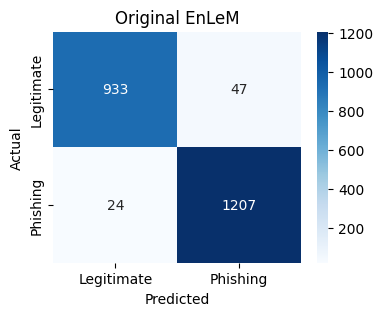

In [10]:
enlem = create_enlem()

enlem.fit(X_train_scaled, y_train)

pred_enlem = enlem.predict(X_test_scaled)

evaluate_model(
    "Original EnLeM",
    y_test,
    pred_enlem
)

show_confusion_matrix(
    "Original EnLeM",
    y_test,
    pred_enlem
)

In [11]:
selector = SelectKBest(
    score_func=mutual_info_classif,
    k=20
)

X_train_mi = selector.fit_transform(X_train_scaled, y_train)
X_valid_mi = selector.transform(X_valid_scaled)
X_test_mi = selector.transform(X_test_scaled)

selected_features = X.columns[selector.get_support()]

print("Selected features:")
print(list(selected_features))

Selected features:
['having_at_symbol', 'double_slash_redirecting', 'prefix_suffix', 'having_sub_domain', 'sslfinal_state', 'domain_registration_length', 'port', 'https_token', 'request_url', 'url_of_anchor', 'links_in_tags', 'sfh', 'abnormal_url', 'rightclick', 'dnsrecord', 'web_traffic', 'page_rank', 'google_index', 'links_pointing_to_page', 'statistical_report']



 EnLeM + Mutual Information
              precision    recall  f1-score   support

  Legitimate       0.97      0.94      0.95       980
    Phishing       0.95      0.98      0.96      1231

    accuracy                           0.96      2211
   macro avg       0.96      0.96      0.96      2211
weighted avg       0.96      0.96      0.96      2211



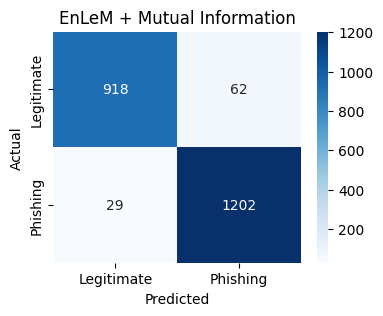

In [12]:
enlem_mi = create_enlem()

enlem_mi.fit(X_train_mi, y_train)

pred_enlem_mi = enlem_mi.predict(X_test_mi)

evaluate_model(
    "EnLeM + Mutual Information",
    y_test,
    pred_enlem_mi
)

show_confusion_matrix(
    "EnLeM + Mutual Information",
    y_test,
    pred_enlem_mi
)

In [13]:
input_dim = X_train_scaled.shape[1]
latent_dim = 8

inputs = tf.keras.Input(shape=(input_dim,))

encoded = tf.keras.layers.Dense(
    16,
    activation="relu"
)(inputs)

latent = tf.keras.layers.Dense(
    latent_dim,
    activation="relu",
    name="latent_features"
)(encoded)

decoded = tf.keras.layers.Dense(
    16,
    activation="relu"
)(latent)

outputs = tf.keras.layers.Dense(
    input_dim,
    activation="linear"
)(decoded)

autoencoder = tf.keras.Model(inputs, outputs)

encoder = tf.keras.Model(
    inputs,
    latent
)

autoencoder.compile(
    optimizer="adam",
    loss="mse"
)

autoencoder.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 30)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 16)             │           496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ latent_features (Dense)         │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 16)             │           144 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 30)             │           510 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,286 (5.02 KB)

 Trainable params: 1,286 (5.02 KB)

 Non-trainable params: 0 (0.00 B)

In [14]:
early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=8,
    restore_best_weights=True
)

history = autoencoder.fit(
    X_train_scaled,
    X_train_scaled,
    validation_data=(X_valid_scaled, X_valid_scaled),
    epochs=100,
    batch_size=64,
    callbacks=[early_stopping],
    verbose=1
)

Epoch 1/100
111/111 ━━━━━━━━━━━━━━━━━━━━ 5s 22ms/step - loss: 0.9780 - val_loss: 0.8776
Epoch 2/100
111/111 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.7525 - val_loss: 0.6384
Epoch 3/100
111/111 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.5940 - val_loss: 0.5582
Epoch 4/100
111/111 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.5378 - val_loss: 0.5177
Epoch 5/100
111/111 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.5046 - val_loss: 0.4897
Epoch 6/100
111/111 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.4804 - val_loss: 0.4687
Epoch 7/100
111/111 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.4614 - val_loss: 0.4518
Epoch 8/100
111/111 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.4451 - val_loss: 0.4365
Epoch 9/100
111/111 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.4291 - val_loss: 0.4218
Epoch 10/100
111/111 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.4141 - val_loss: 0.4092
Epoch 11/100
111/111 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.4013 - val_loss: 0.3985
Epoch 12/100
111/111 ━━━━━━━━━━━━━━━━━━━

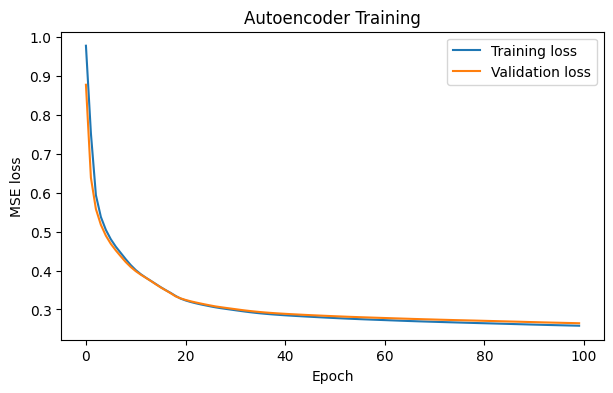

In [15]:
plt.figure(figsize=(7, 4))
plt.plot(history.history["loss"], label="Training loss")
plt.plot(history.history["val_loss"], label="Validation loss")
plt.xlabel("Epoch")
plt.ylabel("MSE loss")
plt.legend()
plt.title("Autoencoder Training")
plt.show()

In [16]:
X_train_encoded = encoder.predict(X_train_scaled)
X_valid_encoded = encoder.predict(X_valid_scaled)
X_test_encoded = encoder.predict(X_test_scaled)

print(X_train_encoded.shape)

222/222 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
56/56 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step
70/70 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
(7075, 8)



 Autoencoder + EnLeM
              precision    recall  f1-score   support

  Legitimate       0.96      0.93      0.94       980
    Phishing       0.94      0.97      0.96      1231

    accuracy                           0.95      2211
   macro avg       0.95      0.95      0.95      2211
weighted avg       0.95      0.95      0.95      2211



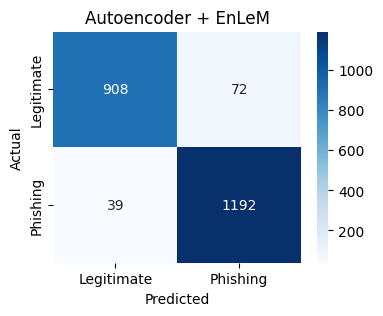

In [17]:
enlem_autoencoder = create_enlem()

enlem_autoencoder.fit(
    X_train_encoded,
    y_train
)

pred_autoencoder = enlem_autoencoder.predict(
    X_test_encoded
)

evaluate_model(
    "Autoencoder + EnLeM",
    y_test,
    pred_autoencoder
)

show_confusion_matrix(
    "Autoencoder + EnLeM",
    y_test,
    pred_autoencoder
)

In [18]:
NUM_CLIENTS = 5

client_indices = np.array_split(
    np.arange(len(X_train_scaled)),
    NUM_CLIENTS
)

clients = []

for i, indices in enumerate(client_indices):
    clients.append({
        "X": X_train_scaled[indices],
        "y": np.array(y_train)[indices]
    })

for i, client in enumerate(clients):
    print(
        f"Client {i+1}:",
        client["X"].shape,
        np.bincount(client["y"])
    )

Client 1: (1415, 30) [635 780]
Client 2: (1415, 30) [635 780]
Client 3: (1415, 30) [631 784]
Client 4: (1415, 30) [618 797]
Client 5: (1415, 30) [615 800]


In [19]:
def build_autoencoder(input_dim, latent_dim=8):
    inputs = tf.keras.Input(shape=(input_dim,))

    x = tf.keras.layers.Dense(16, activation="relu")(inputs)
    latent = tf.keras.layers.Dense(
        latent_dim,
        activation="relu",
        name="latent_features"
    )(x)

    x = tf.keras.layers.Dense(16, activation="relu")(latent)
    outputs = tf.keras.layers.Dense(
        input_dim,
        activation="linear"
    )(x)

    autoencoder = tf.keras.Model(inputs, outputs)
    encoder = tf.keras.Model(inputs, latent)

    autoencoder.compile(
        optimizer="adam",
        loss="mse"
    )

    return autoencoder, encoder

In [20]:
def federated_average(weight_sets, client_sizes):
    total_samples = np.sum(client_sizes)

    averaged_weights = []

    for layer_weights in zip(*weight_sets):
        weighted_layer = np.zeros_like(layer_weights[0])

        for weights, size in zip(layer_weights, client_sizes):
            weighted_layer += weights * (size / total_samples)

        averaged_weights.append(weighted_layer)

    return averaged_weights

In [21]:
FEDERATED_ROUNDS = 10
LOCAL_EPOCHS = 5
BATCH_SIZE = 64

global_autoencoder, global_encoder = build_autoencoder(
    input_dim=input_dim,
    latent_dim=latent_dim
)

for federated_round in range(FEDERATED_ROUNDS):

    local_weights = []
    client_sizes = []

    for client in clients:

        local_autoencoder, _ = build_autoencoder(
            input_dim=input_dim,
            latent_dim=latent_dim
        )

        local_autoencoder.set_weights(
            global_autoencoder.get_weights()
        )

        local_autoencoder.fit(
            client["X"],
            client["X"],
            epochs=LOCAL_EPOCHS,
            batch_size=BATCH_SIZE,
            verbose=0
        )

        local_weights.append(
            local_autoencoder.get_weights()
        )

        client_sizes.append(
            len(client["X"])
        )

    averaged_weights = federated_average(
        local_weights,
        client_sizes
    )

    global_autoencoder.set_weights(
        averaged_weights
    )

    print(
        f"Completed federated round "
        f"{federated_round + 1}/{FEDERATED_ROUNDS}"
    )

Completed federated round 1/10
Completed federated round 2/10
Completed federated round 3/10
Completed federated round 4/10
Completed federated round 5/10
Completed federated round 6/10
Completed federated round 7/10
Completed federated round 8/10
Completed federated round 9/10
Completed federated round 10/10


In [22]:
global_encoder = tf.keras.Model(
    global_autoencoder.input,
    global_autoencoder.get_layer("latent_features").output
)

X_test_federated_encoded = global_encoder.predict(
    X_test_scaled
)

70/70 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step


In [23]:
local_models = []

for i, client in enumerate(clients):

    X_client_encoded = global_encoder.predict(
        client["X"],
        verbose=0
    )

    local_model = create_enlem()

    local_model.fit(
        X_client_encoded,
        client["y"]
    )

    local_models.append(local_model)

    print(f"Trained local EnLeM model {i+1}")

Trained local EnLeM model 1
Trained local EnLeM model 2
Trained local EnLeM model 3
Trained local EnLeM model 4
Trained local EnLeM model 5


In [24]:
client_predictions = []

for local_model in local_models:
    predictions = local_model.predict(
        X_test_federated_encoded
    )
    client_predictions.append(predictions)

client_predictions = np.array(client_predictions)

print(client_predictions.shape)

(5, 2211)



 Federated Autoencoder + Local EnLeM
              precision    recall  f1-score   support

  Legitimate       0.90      0.90      0.90       980
    Phishing       0.92      0.92      0.92      1231

    accuracy                           0.91      2211
   macro avg       0.91      0.91      0.91      2211
weighted avg       0.91      0.91      0.91      2211



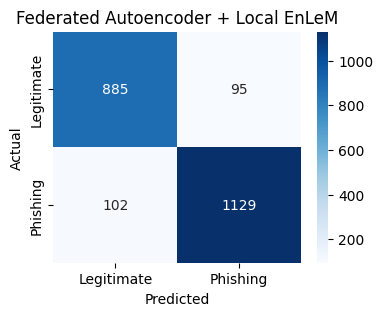

In [25]:
federated_predictions = (
    np.mean(client_predictions, axis=0) >= 0.5
).astype(int)

evaluate_model(
    "Federated Autoencoder + Local EnLeM",
    y_test,
    federated_predictions
)

show_confusion_matrix(
    "Federated Autoencoder + Local EnLeM",
    y_test,
    federated_predictions
)

In [26]:
def build_classifier(input_dim):
    model = tf.keras.Sequential([
        tf.keras.layers.Input(shape=(input_dim,)),
        tf.keras.layers.Dense(32, activation="relu"),
        tf.keras.layers.Dropout(0.2),
        tf.keras.layers.Dense(16, activation="relu"),
        tf.keras.layers.Dense(1, activation="sigmoid")
    ])

    model.compile(
        optimizer="adam",
        loss="binary_crossentropy",
        metrics=["accuracy"]
    )

    return model

In [27]:
global_classifier = build_classifier(
    input_dim=X_train_scaled.shape[1]
)

FEDERATED_CLASSIFIER_ROUNDS = 10
LOCAL_CLASSIFIER_EPOCHS = 3

for federated_round in range(FEDERATED_CLASSIFIER_ROUNDS):

    local_weights = []
    client_sizes = []

    for client in clients:

        local_model = build_classifier(
            input_dim=X_train_scaled.shape[1]
        )

        local_model.set_weights(
            global_classifier.get_weights()
        )

        local_model.fit(
            client["X"],
            client["y"],
            epochs=LOCAL_CLASSIFIER_EPOCHS,
            batch_size=64,
            verbose=0
        )

        local_weights.append(
            local_model.get_weights()
        )

        client_sizes.append(
            len(client["X"])
        )

    averaged_weights = federated_average(
        local_weights,
        client_sizes
    )

    global_classifier.set_weights(
        averaged_weights
    )

    print(
        f"Completed classifier round "
        f"{federated_round + 1}/{FEDERATED_CLASSIFIER_ROUNDS}"
    )

Completed classifier round 1/10
Completed classifier round 2/10
Completed classifier round 3/10
Completed classifier round 4/10
Completed classifier round 5/10
Completed classifier round 6/10
Completed classifier round 7/10
Completed classifier round 8/10
Completed classifier round 9/10
Completed classifier round 10/10


70/70 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step

 Federated Neural Classifier
              precision    recall  f1-score   support

  Legitimate       0.94      0.92      0.93       980
    Phishing       0.94      0.95      0.94      1231

    accuracy                           0.94      2211
   macro avg       0.94      0.93      0.93      2211
weighted avg       0.94      0.94      0.94      2211



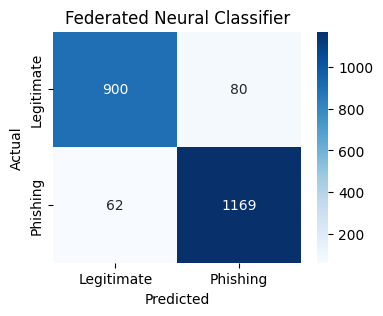

In [28]:
federated_probabilities = global_classifier.predict(
    X_test_scaled
).ravel()

federated_nn_predictions = (
    federated_probabilities >= 0.5
).astype(int)

evaluate_model(
    "Federated Neural Classifier",
    y_test,
    federated_nn_predictions
)

show_confusion_matrix(
    "Federated Neural Classifier",
    y_test,
    federated_nn_predictions
)

In [29]:
results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="F1-score",
    ascending=False
).reset_index(drop=True)

results_df

,Model,Accuracy,Precision,Recall,F1-score
0,Original EnLeM,0.967888,0.962520,0.980504,0.971429
1,EnLeM + Mutual Information,0.958842,0.950949,0.976442,0.963527
2,Autoencoder + EnLeM,0.949796,0.943038,0.968318,0.955511
3,Federated Neural Classifier,0.935776,0.935949,0.949634,0.942742
4,Federated Autoencoder + Local EnLeM,0.910900,0.922386,0.917141,0.919756


In [30]:
results_display = results_df.copy()

for column in [
    "Accuracy",
    "Precision",
    "Recall",
    "F1-score"
]:
    results_display[column] = (
        results_display[column] * 100
    ).round(2)

results_display

,Model,Accuracy,Precision,Recall,F1-score
0,Original EnLeM,96.79,96.25,98.05,97.14
1,EnLeM + Mutual Information,95.88,95.09,97.64,96.35
2,Autoencoder + EnLeM,94.98,94.30,96.83,95.55
3,Federated Neural Classifier,93.58,93.59,94.96,94.27
4,Federated Autoencoder + Local EnLeM,91.09,92.24,91.71,91.98


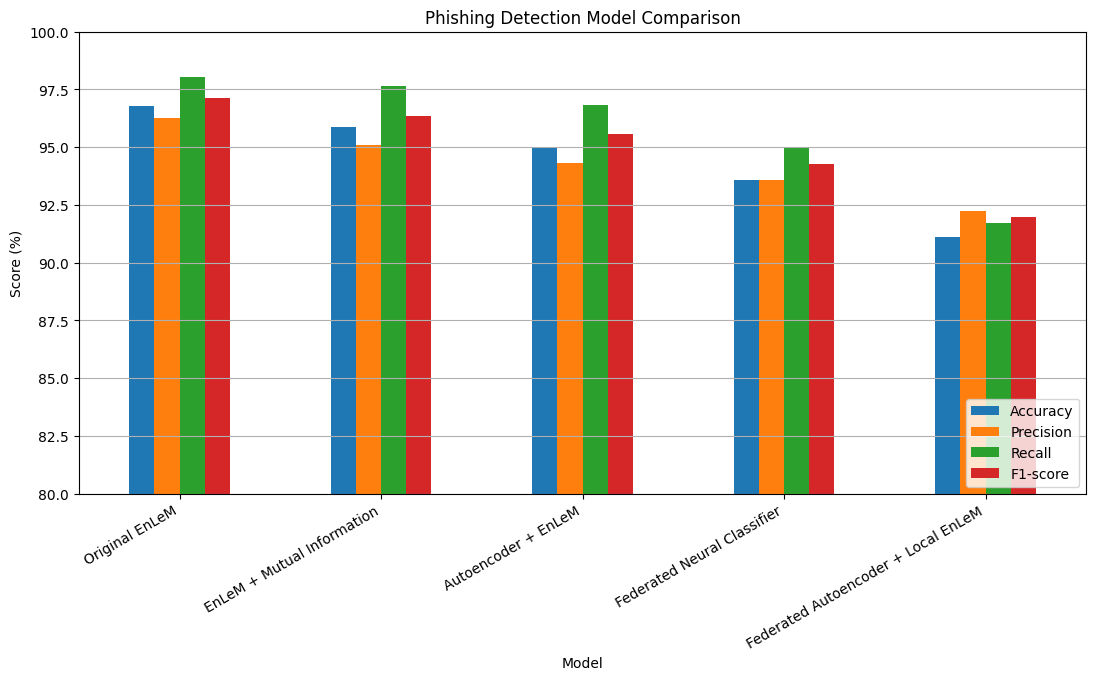

In [31]:
plot_df = results_display.set_index("Model")

plot_df[
    ["Accuracy", "Precision", "Recall", "F1-score"]
].plot(
    kind="bar",
    figsize=(13, 6)
)

plt.title("Phishing Detection Model Comparison")
plt.ylabel("Score (%)")
plt.ylim(80, 100)
plt.xticks(rotation=30, ha="right")
plt.grid(axis="y")
plt.legend(loc="lower right")
plt.show()

In [32]:
results_display.to_csv(
    "phishing_model_comparison.csv",
    index=False
)

from google.colab import files
files.download("phishing_model_comparison.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>